# Terrorism Hotspots
In this notebook, we will be doing EDA on Global Terrorism Database incident records from 1970–2017. The goal is to gain insight into the nature and distribution of terrorist incidents around the world. 

## Importing the Data

In [1]:
import pandas as pd

# https://platform.stratascratch.com/data-projects/terrorism-hotspots
df = pd.read_csv('datasets/globalterrorismdb_0718dist.csv')
df.head()

C:\Users\j_yam\AppData\Local\Temp\ipykernel_11160\1126470254.py:3: DtypeWarning: Columns (0: approxdate, 1: resolution, 2: attacktype2_txt, 3: attacktype3_txt, 4: gsubname2, 5: gname3, 6: gsubname3, 7: claimmode2_txt, 8: claimmode3_txt, 9: weaptype3_txt, 10: weapsubtype3_txt, 11: weaptype4_txt, 12: weapsubtype4_txt, 13: divert, 14: kidhijcountry, 15: ransomnote) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('datasets/globalterrorismdb_0718dist.csv')


,Unnamed: 0,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,...,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
0,0,197000000001,1970,7,2,NaN,0,NaN,58,Dominican Republic,...,NaN,NaN,NaN,NaN,PGIS,0,0,0,0,NaN
1,1,197000000002,1970,0,0,NaN,0,NaN,130,Mexico,...,NaN,NaN,NaN,NaN,PGIS,0,1,1,1,NaN
2,2,197001000001,1970,1,0,NaN,0,NaN,160,Philippines,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN
3,3,197001000002,1970,1,0,NaN,0,NaN,78,Greece,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN
4,4,197001000003,1970,1,0,NaN,0,NaN,101,Japan,...,NaN,NaN,NaN,NaN,PGIS,-9,-9,1,1,NaN


In [2]:
df.shape

(181691, 136)

There's a lot of columns here, so let's remove the ones where more than 80% of the rows are null values to pare down the dataset and make it more manageble and informative. There's a repeated index column called "Unnamed: 0" that can be dropped as well.

In [3]:
del df['Unnamed: 0']
percent_missing = df.isnull().sum() * 100 / len(df)
less_than_80_percent_missing = percent_missing[percent_missing < 80].sort_values()
less_than_80_percent_missing

eventid         0.000000
iyear           0.000000
imonth          0.000000
iday            0.000000
extended        0.000000
                 ...    
propcomment    68.100236
location       69.456385
motive         72.171984
scite3         76.049447
propvalue      78.541039
Length: 67, dtype: float64

In [4]:
df = df.filter(less_than_80_percent_missing.index.tolist(), axis=1)
df.head()

,eventid,iyear,imonth,iday,extended,country,country_txt,region,region_txt,vicinity,...,nperps,ransom,scite2,propextent,propextent_txt,propcomment,location,motive,scite3,propvalue
0,197000000001,1970,7,2,0,58,Dominican Republic,2,Central America & Caribbean,0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,197000000002,1970,0,0,0,130,Mexico,1,North America,0,...,7.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,197001000001,1970,1,0,0,160,Philippines,5,Southeast Asia,0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,197001000002,1970,1,0,0,78,Greece,8,Western Europe,0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,197001000003,1970,1,0,0,101,Japan,4,East Asia,0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.columns

Index(['eventid', 'iyear', 'imonth', 'iday', 'extended', 'country',
       'country_txt', 'region', 'region_txt', 'vicinity', 'targtype1',
       'success', 'suicide', 'crit3', 'crit2', 'crit1', 'targtype1_txt',
       'attacktype1', 'attacktype1_txt', 'dbsource', 'weaptype1',
       'weaptype1_txt', 'individual', 'gname', 'INT_LOG', 'property',
       'INT_MISC', 'INT_IDEO', 'INT_ANY', 'doubtterr', 'multiple',
       'specificity', 'ishostkid', 'guncertain1', 'provstate', 'city',
       'target1', 'natlty1_txt', 'natlty1', 'latitude', 'longitude', 'nkill',
       'targsubtype1', 'targsubtype1_txt', 'nwound', 'weapsubtype1',
       'weapsubtype1_txt', 'corp1', 'nkillus', 'nwoundus', 'claimed',
       'summary', 'scite1', 'nkillter', 'weapdetail', 'nwoundte', 'nperpcap',
       'nperps', 'ransom', 'scite2', 'propextent', 'propextent_txt',
       'propcomment', 'location', 'motive', 'scite3', 'propvalue'],
      dtype='str')

Now only around half the columns remain, which will make the dataframe easier to work with.

## Years

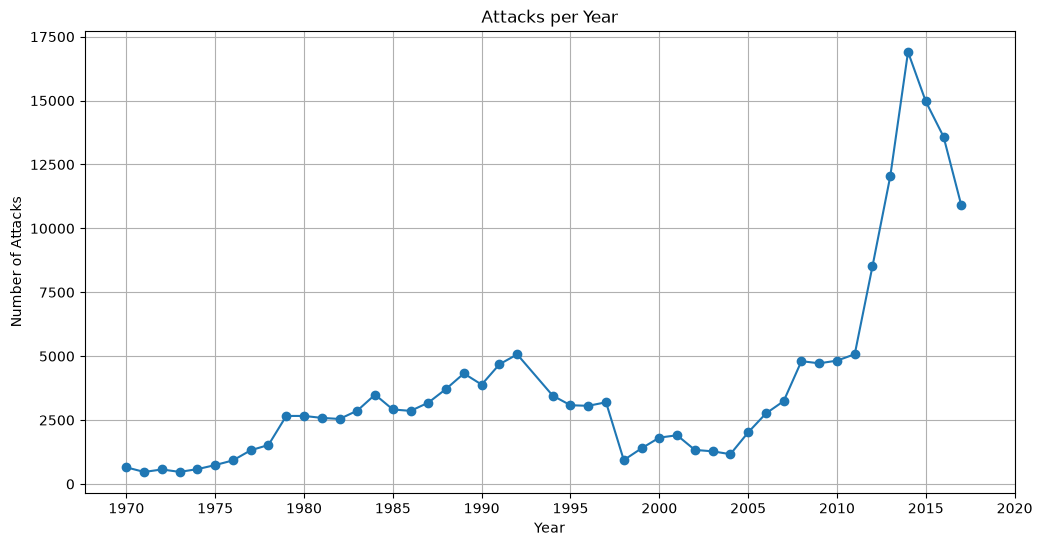

In [9]:
import matplotlib.pyplot as plt

attacks_per_year = df.groupby('iyear')['eventid'].count()
attacks_per_year.plot(
    figsize=(12, 6),
    marker='o',
    xlabel='Year',
    ylabel='Number of Attacks',
    title='Attacks per Year'
)
plt.xticks(range(1970, 2021, 5))
plt.grid()

The number of terrorist attacks remained relatively stable from 1970 to 2010, after which it rose sharply. It reached its peak during 2014 before declining again for the next few years.

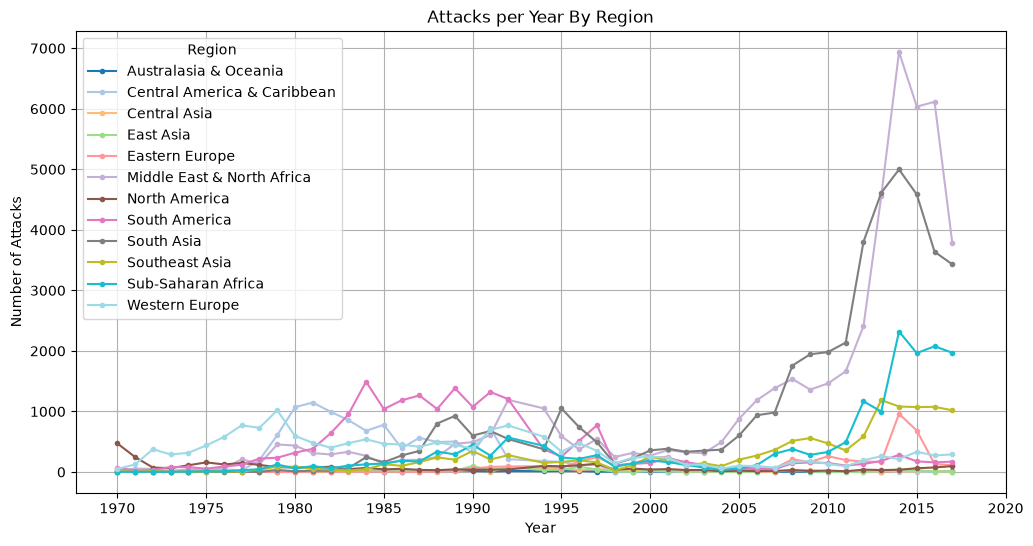

In [8]:
attacks_per_year_by_region = df.groupby(['iyear', 'region_txt'])['eventid'].count().unstack()
attacks_per_year_by_region.plot(
    figsize=(12, 6),
    marker='.',
    xlabel='Year',
    ylabel='Number of Attacks',
    title='Attacks per Year By Region',
    colormap='tab20' # 10 default colors is not enough
)
plt.xticks(range(1970, 2021, 5))
plt.grid()
plt.legend(title='Region')

After breaking it down by region, we can see that the Middle East, North Africa, and South Asia are mostly responsible for the spike in attacks shown on the previous graph. Sub-Saharan Africa, Southeast Asia, and Central Asia show a slight increase during that time and the rest of the regions do not show any correlation.

Let's see zoom in on 2014 to see what was happening in the top two regions (Middle East & North Africa and South Asia) during this time.

In [41]:
me_na_2014 = df[(df['iyear'] == 2014) & (df['region_txt'] == 'Middle East & North Africa')]
print(me_na_2014['targtype1_txt'].value_counts().head())
print(me_na_2014['natlty1_txt'].value_counts().head())
print(me_na_2014['gname'].value_counts().head())

targtype1_txt
Private Citizens & Property    2022
Military                       1513
Police                         1071
Government (General)            532
Business                        389
Name: count, dtype: int64
natlty1_txt
Iraq      3924
Yemen      741
Libya      670
Egypt      364
Israel     359
Name: count, dtype: int64
gname
Unknown                                        4416
Islamic State of Iraq and the Levant (ISIL)    1248
Al-Qaida in the Arabian Peninsula (AQAP)        291
Houthi extremists (Ansar Allah)                 135
Muslim extremists                               106
Name: count, dtype: int64


In [39]:
# ISIL as a percentage of known groups
1248 / (me_na_2014['gname'].dropna().count() - 1248 - 4416)

np.float64(0.9788235294117648)

A look at some columns of interest reveals that many private citizens and their properties in Iraq were targeted by an unknown group. This explosion in terrorist activity marks the beginnings of the War in Iraq. Although most of the attacks are listed as unknown, it is likely that they are the work of the Islamic State of Iraq and the Levant (ISIL), which is responsible for 98% of attacks by a known group.

In [40]:
sa_2014 = df[(df['iyear'] == 2014) & (df['region_txt'] == 'South Asia')]
print(sa_2014['targtype1_txt'].value_counts().head())
print(sa_2014['natlty1_txt'].value_counts().head())
print(sa_2014['gname'].value_counts().head())

targtype1_txt
Police                         1130
Private Citizens & Property     955
Military                        762
Government (General)            558
Unknown                         403
Name: count, dtype: int64
natlty1_txt
Pakistan         2106
Afghanistan      1553
India             863
Bangladesh        129
International     122
Name: count, dtype: int64
gname
Unknown                            2832
Taliban                            1034
Maoists                             252
Tehrik-i-Taliban Pakistan (TTP)     167
Baloch Republican Army (BRA)        101
Name: count, dtype: int64


In [42]:
# Taliban as a percentage of known groups
1034 / (sa_2014['gname'].dropna().count() - 1034 - 2832)

np.float64(0.9134275618374559)

In South Asia, many police in Pakistan and Afghanistan were targeted by terrorist attacks. Chronologically, this corresponds with the War in North-West Pakistan and War in Afghanistan. Similarly to before, the origin of most attacks is unknown but the Taliban is responsible for the 91% of known incidents it suggests that they would also be responsible for most of the unknown incidents as well.

## Casualties

Text(0, 0.5, 'Number of Casualties')

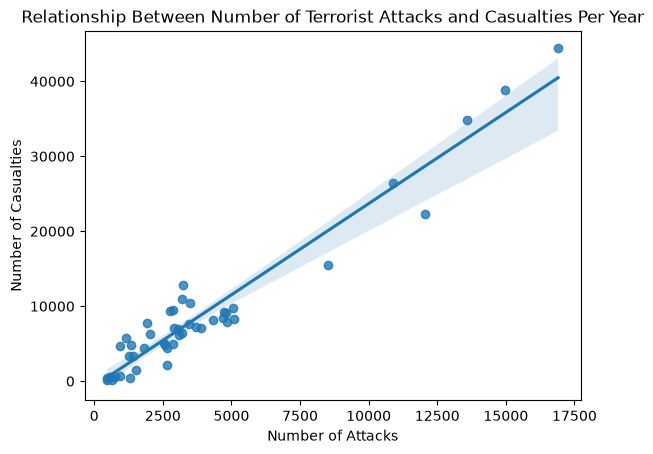

In [77]:
import seaborn as sns

deaths_per_year = df.groupby('iyear').agg({
    'nkill': 'sum', # number of deaths per year
    'eventid': 'count' # number of incidents per year
})

sns.regplot(x=deaths_per_year['eventid'], y=deaths_per_year['nkill'])
plt.title('Relationship Between Number of Terrorist Attacks and Casualties Per Year')
plt.xlabel('Number of Attacks')
plt.ylabel('Number of Casualties')

In [54]:
deaths_per_year.corr(attacks_per_year)

np.float64(0.966004953717957)

The number of deaths is strongly correlated with the number of attacks with a coefficient of 0.97, which is not surprising. From the graph, we can discern a linear relationship between casualty count and attack intensity. Now let's look for outliers that deviate from this pattern.

In [94]:
print(df.sort_values('nkill', ascending=False)[['iyear', 'imonth', 'iday', 'nkill', 'country_txt', 'scite2']].head())

        iyear  imonth  iday   nkill    country_txt  \
133518   2014       6    12  1570.0           Iraq   
73126    2001       9    11  1384.0  United States   
73127    2001       9    11  1383.0  United States   
55934    1994       4    13  1180.0         Rwanda   
136283   2014       8     3   953.0           Iraq   

                                                   scite2  
133518  "Scene of Iraqi Massacre Becomes Shiite Pilgri...  
73126   Lindsay Kines, �United States on high alert af...  
73127   Lindsay Kines, �United States on high alert af...  
55934                                                 NaN  
136283  "Dozens of Yazidi women 'sold into marriage' b...  


Notable outliers with a large number of casualties (>1000) are:
- The 9/11 attacks on the Twin Towers of the World Trade Center
- The Camp Speicher massacre
- Kigali church killings during the Rwandan genocide

## Methods

In [96]:
common_methods = df.groupby('attacktype1_txt')['eventid'].count().sort_values(ascending=False)
common_methods

attacktype1_txt
Bombing/Explosion                      88255
Armed Assault                          42669
Assassination                          19312
Hostage Taking (Kidnapping)            11158
Facility/Infrastructure Attack         10356
Unknown                                 7276
Unarmed Assault                         1015
Hostage Taking (Barricade Incident)      991
Hijacking                                659
Name: eventid, dtype: int64

The most common method of attack is Bombing/Explosion (88255 instances), at over twice the rate of the second most common method of Armed Assault (42669 instances). The next most common methods are Assasination, Hostage Taking (Kidnapping), and Facility/Infrastructure Attack which have around 10-20k instances. 

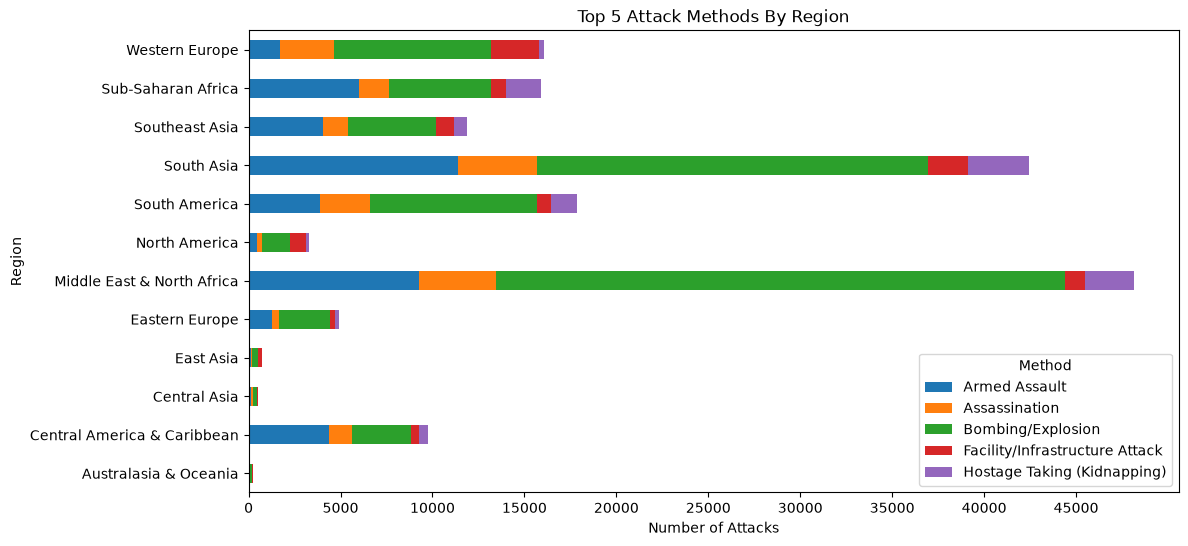

In [97]:
top_methods = df.query('attacktype1_txt in @common_methods.head().index.tolist()')
top_methods_by_region = top_methods.groupby(['region_txt', 'attacktype1_txt'])['eventid'].count().unstack()
top_methods_by_region.plot.barh(
    figsize=(12, 6),
    stacked=True,
    xlabel='Number of Attacks',
    ylabel='Region',
    title='Top 5 Attack Methods By Region',
)
plt.xticks(range(0, 50000, 5000))
plt.legend(title='Method')

Bombing/Explosion accounts for most of the attacks in the Middle East & North Africa. South Asia has the highest rates of Armed Assault and Hostage Taking (Kidnapping).

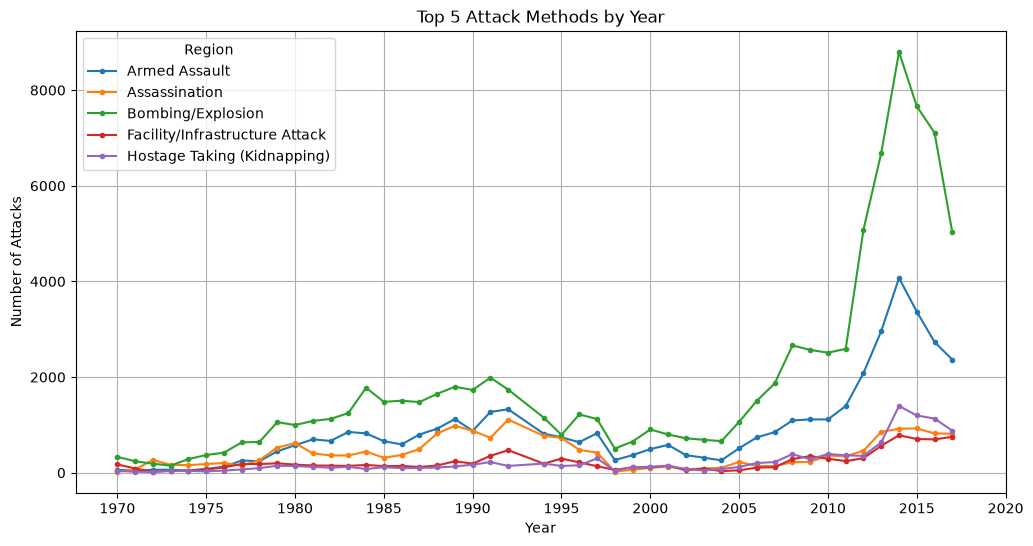

In [98]:
methods_by_time = top_methods.groupby(['iyear', 'attacktype1_txt'])['eventid'].count().unstack()
methods_by_time.plot(
    figsize=(12, 6),
    marker='.',
    xlabel='Year',
    ylabel='Number of Attacks',
    title='Top 5 Attack Methods by Year',
)
plt.xticks(range(1970, 2021, 5))
plt.grid()
plt.legend(title='Region')

With the exception of a few years in the early 70s, Bombing/Explosion is consistently the most popular attack method employed by terrorists. The increase in bombings correlates with the increase in ISIL activity, suggesting that this is the group's preferred method of attack. Other categories such as Facility/Infrastructure Attack and Hostage Taking (Kidnapping) tend to occur at similar rates throughout time.

## Locations

C:\Users\j_yam\AppData\Local\Temp\ipykernel_11160\856124566.py:5: DeprecationWarning: The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.
  fig = px.choropleth(


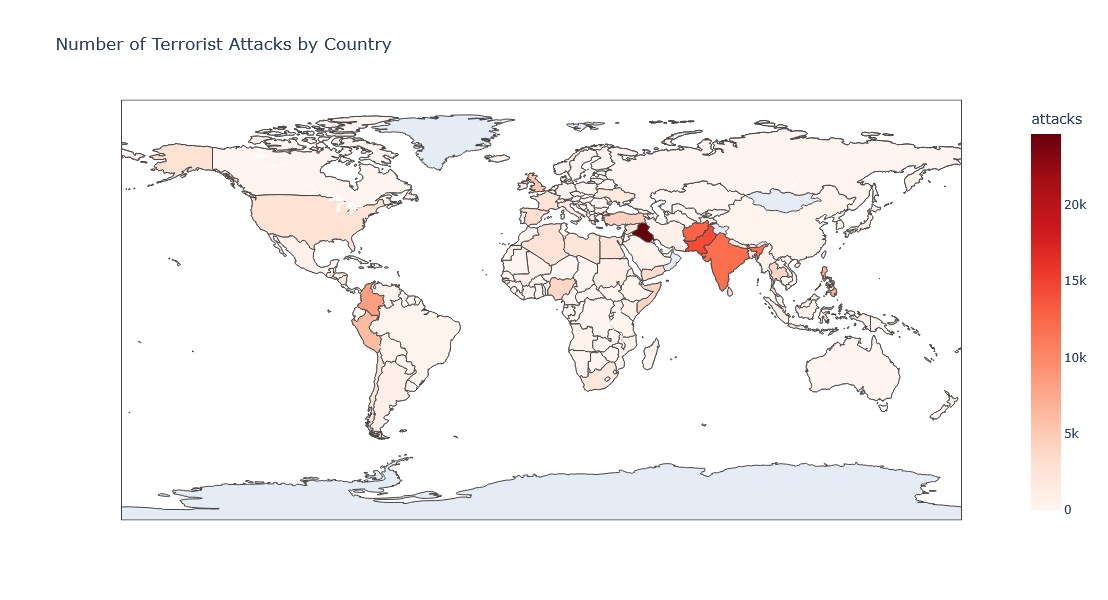

In [99]:
import plotly.express as px

attacks_by_country = df.groupby('country_txt')['eventid'].count().reset_index(name='attacks')

fig = px.choropleth(
    attacks_by_country,
    locations='country_txt',
    locationmode='country names',
    color='attacks',
    color_continuous_scale='Reds',
    title='Number of Terrorist Attacks by Country',
    width=1000,
    height=600
)

fig.show()

The map shows a strong regional concentration of terrorist attacks in Iraq, which has been the site of around 24k attacks. There is also a large cluster of attacks in the Pakistan-Afghanistan-India area. However, it is important to note that this is map only takes account the number of attacks and not factors such as intensity, duration, scale, etc. that could define terrorism risk.